# 03 — Credit-Risk Modeling and Temporal Validation

**Purpose:** evaluate whether borrower and loan characteristics predict the observed default outcome on later LendingClub loan vintages.

This notebook runs three related experiments:

1. **Pooled model (main experiment):** both 36- and 60-month loans, with loan term included as a predictor.
2. **36-month model:** a separate model for 36-month loans.
3. **60-month model:** a separate model for 60-month loans.

Each experiment uses expanding-window chronological backtests. For a test year `t`, the model is trained on years before `t - 1`, the immediately preceding year is used for validation and threshold selection, and year `t` is held out for testing. No test-year records are used for training, model selection or threshold selection.

## Important interpretation limits

- The target is the **observed resolved status** in this LendingClub snapshot: Fully Paid = 0; Charged Off / Default = 1. It is not a precisely dated 36-month or 60-month event label.
- Notebook 1 keeps cohorts with at least 99.5% resolved status. This is a project rule, not proof that every loan has completed its contractual life.
- The intended prediction point is **loan origination after underwriting terms have been assigned**. `grade`, `sub_grade` and `int_rate` are therefore permitted. A pre-underwriting model would need to remove them.
- Macroeconomic variables are not included yet. This notebook tests origination year and quarter as simple time-context features; it does not establish causal effects.
- Multiple loans from one borrower may exist. The curated dataset does not retain a borrower identifier, so borrower-level grouped splitting is not possible here.

## Full population versus 100,000-row sample

The notebook automatically prefers `data/processed/featured_data_full.csv` (all eligible records) when it exists. Otherwise, it uses `data/processed/featured_data.csv` (the 100,000-row benchmark sample). The sample can be used to check the workflow, but final conclusions—especially for 60-month loans—should use the full eligible population created by the revised upstream notebooks.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from threadpoolctl import threadpool_limits

warnings.filterwarnings("ignore", category=FutureWarning)
threadpool_limits(limits=2)  # avoid excessive BLAS/OpenMP thread creation during repeated folds

RANDOM_STATE = 42
TARGET_RECALL = 0.70
MIN_TRAIN_ROWS = 1_000
MIN_VALIDATION_ROWS = 200
MIN_TEST_ROWS = 200
MIN_TRAIN_PER_CLASS = 20
MIN_VALIDATION_TEST_PER_CLASS = 10
CALIBRATION_FOLDS = 2
N_JOBS = 1  # conservative default; increase only if your machine has spare resources
MIN_SEGMENT_ROWS = 100
MIN_SEGMENT_DEFAULTS = 20
MIN_SEGMENT_NONDEFAULTS = 20

# The full output is preferred. The current sample is a supported fallback.
INPUT_FILENAMES = ["featured_data_full.csv", "featured_data.csv"]

def find_project_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        processed = candidate / "data" / "processed"
        if any((processed / name).exists() for name in INPUT_FILENAMES):
            return candidate
    raise FileNotFoundError(
        "Could not locate data/processed/featured_data_full.csv or featured_data.csv. "
        "Run Notebooks 1 and 2 first, then open this notebook from the project root "
        "or the notebooks/ directory."
    )

PROJECT_ROOT = find_project_root()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

INPUT_PATH = next(
    (PROCESSED_DIR / name for name in INPUT_FILENAMES if (PROCESSED_DIR / name).exists()),
    None,
)
if INPUT_PATH is None:
    raise FileNotFoundError("No engineered feature dataset was found.")

print("Project root:", PROJECT_ROOT)
print("Input:", INPUT_PATH)
print("Target recall for threshold selection:", f"{TARGET_RECALL:.0%}")

Project root: n:\SARANYA\GITRepositories\APPS\credit_risk_analytics
Input: n:\SARANYA\GITRepositories\APPS\credit_risk_analytics\data\processed\featured_data_full.csv
Target recall for threshold selection: 70%


## 1. Load and validate the engineered dataset

The date fields remain available for chronological splitting and diagnostics, but they are not part of the baseline predictor set. The target is validated before any models are fitted.

In [2]:
df = pd.read_csv(INPUT_PATH)

required_columns = {"_source_row_id", "issue_date", "issue_year", "issue_quarter", "term", "default"}
missing_required = required_columns - set(df.columns)
if missing_required:
    raise ValueError(f"Required columns are missing: {sorted(missing_required)}")
if df.empty:
    raise ValueError("The engineered dataset is empty.")

df["issue_date"] = pd.to_datetime(df["issue_date"], errors="coerce")
if df["issue_date"].isna().any():
    raise ValueError(f"Found {int(df['issue_date'].isna().sum()):,} invalid issue dates.")

df["issue_year"] = df["issue_date"].dt.year.astype(int)
df["issue_quarter"] = df["issue_date"].dt.quarter.astype(int)
term_digits = df["term"].astype("string").str.extract(r"(\d+)", expand=False)
df["term"] = pd.to_numeric(term_digits, errors="coerce")
if df["term"].isna().any():
    raise ValueError("Some loan terms could not be parsed.")

target = pd.to_numeric(df["default"], errors="coerce")
if target.isna().any() or not set(target.unique()).issubset({0, 1}):
    raise ValueError("The default target must contain only 0 and 1 with no missing values.")
df["default"] = target.astype("int8")

valid_terms = {36, 60}
found_terms = set(df["term"].astype(int).unique())
if not found_terms.issubset(valid_terms):
    raise ValueError(f"Unexpected loan terms found: {sorted(found_terms - valid_terms)}")

if df["_source_row_id"].isna().any() or df["_source_row_id"].duplicated().any():
    raise ValueError("_source_row_id must be present and unique; rerun Notebooks 1 and 2.")

df = df.reset_index(drop=True)
IS_FULL_POPULATION = INPUT_PATH.name == "featured_data_full.csv" or len(df) > 100_000

print("Dataset shape:", df.shape)
print("Origination years:", int(df["issue_year"].min()), "to", int(df["issue_year"].max()))
print("Loan terms:", sorted(df["term"].unique().tolist()))
print("Observed default rate:", f"{df['default'].mean():.2%}")
print("Data scope:", "Full eligible population" if IS_FULL_POPULATION else "Sample / subset")
if IS_FULL_POPULATION and (PROCESSED_DIR / "featured_data.csv").exists():
    sample_rows = sum(1 for _ in open(PROCESSED_DIR / "featured_data.csv", encoding="utf-8")) - 1
    print("Benchmark sample rows available:", f"{sample_rows:,}")
    print("Full population / benchmark multiplier:", round(len(df) / max(sample_rows, 1), 2))
if not IS_FULL_POPULATION:
    print(
        "IMPORTANT: this appears to be the 100,000-row sample. Results are useful for "
        "workflow development, but the 60-month experiment may have limited training data. "
        "Use featured_data_full.csv for final conclusions."
    )

display(
    df.groupby(["term", "issue_year"])
    .agg(loans=("default", "size"), defaults=("default", "sum"), default_rate=("default", "mean"))
    .reset_index()
    .round(4)
)

Dataset shape: (676302, 30)
Origination years: 2007 to 2015
Loan terms: [36, 60]
Observed default rate: 14.87%
Data scope: Full eligible population
Benchmark sample rows available: 100,000
Full population / benchmark multiplier: 6.76


,term,issue_year,loans,defaults,default_rate
0,36,2007,603,158,0.2620
1,36,2008,2393,496,0.2073
2,36,2009,5281,723,0.1369
3,36,2010,9156,1000,0.1092
4,36,2011,14101,1499,0.1063
5,36,2012,43470,5903,0.1358
6,36,2013,100422,12378,0.1233
7,36,2014,162570,22315,0.1373
8,36,2015,283026,42132,0.1489
9,60,2010,3381,757,0.2239


## 2. Define the predictor set and perform a leakage audit

The baseline uses the borrower and loan characteristics curated in Notebook 1 / engineered in Notebook 2. It excludes the target and all origination-date metadata. A second Logistic Regression candidate adds `issue_year` and `issue_quarter` to test whether simple time context contributes predictive information.

The pooled experiment treats `term` as categorical. In the term-specific experiments, `term` is removed because it is constant within the subset.

In [3]:
TARGET_COLUMN = "default"
METADATA_COLUMNS = ["issue_date", "issue_year", "issue_quarter"]
IDENTIFIER_COLUMNS = {
    "id", "loan_id", "member_id", "_source_row_id", "url", "zip_code", "zipcode", "desc", "title"
}
FORBIDDEN_TOKENS = [
    "total_pymnt", "total_rec", "recoveries", "collection_recovery_fee",
    "last_pymnt", "last_credit_pull", "out_prncp", "hardship", "settlement",
    "debt_settlement", "loan_status", "next_pymnt"
]

leakage_columns = [
    col for col in df.columns
    if any(token in col.lower() for token in FORBIDDEN_TOKENS)
]
identifier_columns_present = [col for col in df.columns if col.lower() in IDENTIFIER_COLUMNS]
if leakage_columns:
    raise ValueError(f"Potential post-outcome / leakage columns found: {leakage_columns}")

BASE_FEATURES = [
    col for col in df.columns
    if col not in METADATA_COLUMNS + [TARGET_COLUMN]
    and col.lower() not in IDENTIFIER_COLUMNS
]
if not BASE_FEATURES:
    raise ValueError("No predictor columns remain after removing metadata and identifiers.")

print("Baseline predictor count:", len(BASE_FEATURES))
print("Baseline predictors:", BASE_FEATURES)
print("Identifier / source-row columns excluded:", identifier_columns_present)
print("Leakage audit: no forbidden post-outcome columns detected.")
print("Prediction timing: at origination, after underwriting grade/rate assignment.")

Baseline predictor count: 25
Baseline predictors: ['loan_amnt', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'purpose', 'dti', 'delinq_2yrs', 'inq_last_6mths', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'application_type', 'mort_acc', 'pub_rec_bankruptcies', 'fico_avg', 'income_to_loan', 'installment_to_income']
Identifier / source-row columns excluded: ['_source_row_id']
Leakage audit: no forbidden post-outcome columns detected.
Prediction timing: at origination, after underwriting grade/rate assignment.


## 3. Plan the expanding-window backtests

For each test year `t`:

- **Training:** all eligible records with `issue_year < t - 1`.
- **Validation:** records from year `t - 1` only.
- **Test:** records from year `t` only.

The candidate test years are chosen to cover later vintages while retaining enough prior years for training. Folds that fail the minimum sample or class-count requirements are skipped and recorded. The 60-month experiment has fewer eligible origination vintages than the 36-month experiment; the full eligible population should provide enough rows to test both 2012 and 2013, subject to observed class counts.

In [4]:
EXPERIMENTS = {
    "Pooled": {
        "term": None,
        "test_years": [2012, 2013, 2014, 2015],
        "drop_term_feature": False,
    },
    "36-month": {
        "term": 36,
        "test_years": [2013, 2014, 2015],
        "drop_term_feature": True,
    },
    "60-month": {
        "term": 60,
        "test_years": [2012, 2013],
        "drop_term_feature": True,
    },
}

def class_counts(series):
    counts = series.value_counts().to_dict()
    return int(counts.get(0, 0)), int(counts.get(1, 0))

def make_fold_plan(frame, experiment_name, config):
    subset = frame if config["term"] is None else frame.loc[frame["term"] == config["term"]]
    records = []
    for test_year in config["test_years"]:
        validation_year = test_year - 1
        train = subset.loc[subset["issue_year"] < validation_year]
        validation = subset.loc[subset["issue_year"] == validation_year]
        test = subset.loc[subset["issue_year"] == test_year]
        train_0, train_1 = class_counts(train[TARGET_COLUMN]) if len(train) else (0, 0)
        val_0, val_1 = class_counts(validation[TARGET_COLUMN]) if len(validation) else (0, 0)
        test_0, test_1 = class_counts(test[TARGET_COLUMN]) if len(test) else (0, 0)

        reasons = []
        if len(train) < MIN_TRAIN_ROWS:
            reasons.append(f"training rows < {MIN_TRAIN_ROWS}")
        if min(train_0, train_1) < MIN_TRAIN_PER_CLASS:
            reasons.append(f"training class count < {MIN_TRAIN_PER_CLASS}")
        if len(validation) < MIN_VALIDATION_ROWS:
            reasons.append(f"validation rows < {MIN_VALIDATION_ROWS}")
        if min(val_0, val_1) < MIN_VALIDATION_TEST_PER_CLASS:
            reasons.append(f"validation class count < {MIN_VALIDATION_TEST_PER_CLASS}")
        if len(test) < MIN_TEST_ROWS:
            reasons.append(f"test rows < {MIN_TEST_ROWS}")
        if min(test_0, test_1) < MIN_VALIDATION_TEST_PER_CLASS:
            reasons.append(f"test class count < {MIN_VALIDATION_TEST_PER_CLASS}")

        records.append({
            "experiment": experiment_name,
            "train_years": f"{int(train['issue_year'].min())}–{validation_year - 1}" if len(train) else "none",
            "validation_year": validation_year,
            "test_year": test_year,
            "train_rows": len(train),
            "train_defaults": train_1,
            "validation_rows": len(validation),
            "validation_defaults": val_1,
            "test_rows": len(test),
            "test_defaults": test_1,
            "status": "run" if not reasons else "skip",
            "reason": "; ".join(reasons),
        })
    return records

fold_plan_records = []
for experiment_name, config in EXPERIMENTS.items():
    fold_plan_records.extend(make_fold_plan(df, experiment_name, config))

fold_plan = pd.DataFrame(fold_plan_records)
display(fold_plan)
fold_plan.to_csv(OUTPUT_DIR / "temporal_fold_plan.csv", index=False)

if not (fold_plan["status"] == "run").any():
    raise ValueError(
        "No valid temporal folds were found. Use a larger eligible population or review the split settings."
    )

,experiment,train_years,validation_year,test_year,train_rows,train_defaults,validation_rows,validation_defaults,test_rows,test_defaults,status,reason
0,Pooled,2007–2010,2011,2012,20814,3134,21721,3297,53367,8644,run,
1,Pooled,2007–2011,2012,2013,42535,6431,53367,8644,134804,21024,run,
2,Pooled,2007–2012,2013,2014,95902,15075,134804,21024,162570,22315,run,
3,Pooled,2007–2013,2014,2015,230706,36099,162570,22315,283026,42132,run,
4,36-month,2007–2011,2012,2013,31534,3876,43470,5903,100422,12378,run,
5,36-month,2007–2012,2013,2014,75004,9779,100422,12378,162570,22315,run,
6,36-month,2007–2013,2014,2015,175426,22157,162570,22315,283026,42132,run,
7,60-month,2010–2010,2011,2012,3381,757,7620,1798,9897,2741,run,
8,60-month,2010–2011,2012,2013,11001,2555,9897,2741,34382,8646,run,


## 4. Build leakage-safe preprocessing and candidate models

All imputers, scaling and one-hot encoding are fitted inside each model pipeline using that fold's training records only. Unknown categories in validation/test data are ignored safely.

The candidate models are:

- Logistic Regression (class-weight balanced).
- Logistic Regression with origination year and quarter added.
- Random Forest (balanced subsampling).
- Histogram Gradient Boosting.

Hyperparameters are fixed before evaluating the test folds. This notebook is a model-comparison experiment, not an exhaustive hyperparameter search.

In [5]:
def make_one_hot_encoder(dense=False):
    # Support both current and older scikit-learn parameter names.
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=not dense)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=not dense)

def prepare_feature_frame(frame, use_time_features=False, drop_term=False):
    columns = [col for col in BASE_FEATURES if col in frame.columns]
    if drop_term:
        columns = [col for col in columns if col != "term"]
    X = frame[columns].copy()

    # Treat loan term as a category in the pooled model, not as a continuous quantity.
    if "term" in X.columns:
        X["term"] = X["term"].astype("Int64").astype("string").astype(object)

    if use_time_features:
        X["issue_year"] = frame["issue_year"].astype(float).to_numpy()
        X["issue_quarter"] = frame["issue_quarter"].astype("string").astype(object).to_numpy()

    # Convert pandas extension/string types to ordinary object columns for sklearn imputers.
    numeric_columns = X.select_dtypes(include=["number", "bool"]).columns.tolist()
    categorical_columns = [col for col in X.columns if col not in numeric_columns]
    for col in categorical_columns:
        X[col] = X[col].astype(object)
    return X

def build_preprocessor(X_train, dense=False, scale_numeric=True):
    numeric_columns = X_train.select_dtypes(include=["number", "bool"]).columns.tolist()
    categorical_columns = [col for col in X_train.columns if col not in numeric_columns]

    transformers = []
    if numeric_columns:
        numeric_steps = [("imputer", SimpleImputer(strategy="median", add_indicator=True))]
        if scale_numeric:
            numeric_steps.append(("scaler", StandardScaler()))
        transformers.append(("numeric", Pipeline(numeric_steps), numeric_columns))
    if categorical_columns:
        categorical_pipeline = Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", make_one_hot_encoder(dense=dense)),
        ])
        transformers.append(("categorical", categorical_pipeline, categorical_columns))

    return ColumnTransformer(
        transformers=transformers,
        remainder="drop",
        sparse_threshold=0.0 if dense else 0.3,
    )

def build_candidate(name, X_train):
    if name in {"Logistic Regression", "Logistic Regression + origination time"}:
        preprocessor = build_preprocessor(X_train, dense=False, scale_numeric=True)
        classifier = LogisticRegression(
            max_iter=2500,
            class_weight="balanced",
            solver="lbfgs",
            random_state=RANDOM_STATE,
        )
    elif name == "Random Forest":
        preprocessor = build_preprocessor(X_train, dense=False, scale_numeric=False)
        classifier = RandomForestClassifier(
            n_estimators=80,
            max_depth=12,
            min_samples_leaf=20,
            max_features="sqrt",
            class_weight="balanced_subsample",
            n_jobs=N_JOBS,
            random_state=RANDOM_STATE,
        )
    elif name == "Histogram Gradient Boosting":
        preprocessor = build_preprocessor(X_train, dense=True, scale_numeric=False)
        classifier = HistGradientBoostingClassifier(
            max_iter=100,
            learning_rate=0.06,
            max_leaf_nodes=15,
            min_samples_leaf=30,
            l2_regularization=1.0,
            random_state=RANDOM_STATE,
        )
    else:
        raise ValueError(f"Unknown candidate model: {name}")
    return Pipeline([("preprocess", preprocessor), ("classifier", classifier)])

def calculate_metrics(y_true, probabilities, threshold=0.50, train_prevalence=None):
    y_true = np.asarray(y_true, dtype=int)
    probabilities = np.asarray(probabilities, dtype=float)
    predictions = (probabilities >= threshold).astype(int)
    result = {
        "threshold": float(threshold),
        "rows": int(len(y_true)),
        "actual_default_rate": float(y_true.mean()),
        "predicted_default_rate": float(predictions.mean()),
        "accuracy": accuracy_score(y_true, predictions),
        "default_precision": precision_score(y_true, predictions, zero_division=0),
        "default_recall": recall_score(y_true, predictions, zero_division=0),
        "default_f1": f1_score(y_true, predictions, zero_division=0),
        "average_precision": average_precision_score(y_true, probabilities),
        "roc_auc": roc_auc_score(y_true, probabilities) if len(np.unique(y_true)) == 2 else np.nan,
        "brier_score": brier_score_loss(y_true, probabilities),
    }
    if train_prevalence is not None:
        baseline_prob = np.full(len(y_true), float(train_prevalence))
        result["train_prevalence_brier_baseline"] = brier_score_loss(y_true, baseline_prob)
    return result

def choose_validation_threshold(y_true, probabilities, target_recall=TARGET_RECALL):
    precision_values, recall_values, thresholds = precision_recall_curve(y_true, probabilities)
    eligible = np.where(recall_values[:-1] >= target_recall)[0]
    if len(eligible):
        best_index = eligible[np.argmax(precision_values[eligible])]
        method = f"highest precision subject to recall >= {target_recall:.0%}"
    else:
        f1_values = (
            2 * precision_values[:-1] * recall_values[:-1]
            / (precision_values[:-1] + recall_values[:-1] + 1e-12)
        )
        best_index = int(np.argmax(f1_values))
        method = "best validation F1 (target recall not reached)"
    return {
        "threshold": float(thresholds[best_index]),
        "validation_precision": float(precision_values[best_index]),
        "validation_recall": float(recall_values[best_index]),
        "method": method,
    }

print("Preprocessing and model helper functions are ready.")

Preprocessing and model helper functions are ready.


## 5. Run the pooled, 36-month and 60-month experiments

For every eligible fold, candidate models are ranked using **validation average precision**. The best validation candidate is then calibrated using only the training period (stratified folds within historical training data). The decision threshold is selected on the later validation year and applied once to the untouched test year.

The calibration procedure is not allowed to use validation or test labels when fitting the calibrator. If calibration fails for a fold, the notebook records the fallback and uses the uncalibrated selected model.

In [6]:
CANDIDATE_NAMES = [
    "Logistic Regression",
    "Logistic Regression + origination time",
    "Random Forest",
    "Histogram Gradient Boosting",
]

validation_records = []
test_model_records = []
selected_fold_records = []
experiment_predictions = {}
aggregate_candidate_probabilities = {}

for experiment_name, config in EXPERIMENTS.items():
    print("\n" + "=" * 78)
    print("EXPERIMENT:", experiment_name)
    print("=" * 78)

    subset = df if config["term"] is None else df.loc[df["term"] == config["term"]]
    predictions_for_experiment = []
    eligible_folds = fold_plan.loc[
        (fold_plan["experiment"] == experiment_name) & (fold_plan["status"] == "run")
    ]

    if eligible_folds.empty:
        print("No eligible folds. This experiment is skipped for the current dataset.")
        experiment_predictions[experiment_name] = pd.DataFrame()
        continue

    for _, fold_info in eligible_folds.iterrows():
        test_year = int(fold_info["test_year"])
        validation_year = int(fold_info["validation_year"])
        train = subset.loc[subset["issue_year"] < validation_year].copy()
        validation = subset.loc[subset["issue_year"] == validation_year].copy()
        test = subset.loc[subset["issue_year"] == test_year].copy()

        y_train = train[TARGET_COLUMN].astype(int)
        y_validation = validation[TARGET_COLUMN].astype(int)
        y_test = test[TARGET_COLUMN].astype(int)
        train_prevalence = float(y_train.mean())

        X_train_base = prepare_feature_frame(train, use_time_features=False, drop_term=config["drop_term_feature"])
        X_validation_base = prepare_feature_frame(validation, use_time_features=False, drop_term=config["drop_term_feature"])
        X_test_base = prepare_feature_frame(test, use_time_features=False, drop_term=config["drop_term_feature"])

        X_train_time = prepare_feature_frame(train, use_time_features=True, drop_term=config["drop_term_feature"])
        X_validation_time = prepare_feature_frame(validation, use_time_features=True, drop_term=config["drop_term_feature"])
        X_test_time = prepare_feature_frame(test, use_time_features=True, drop_term=config["drop_term_feature"])

        candidate_models = {}
        validation_scores = {}
        candidate_test_probabilities = {}

        for model_name in CANDIDATE_NAMES:
            uses_time = model_name == "Logistic Regression + origination time"
            Xtr = X_train_time if uses_time else X_train_base
            Xv = X_validation_time if uses_time else X_validation_base
            Xte = X_test_time if uses_time else X_test_base

            model = build_candidate(model_name, Xtr)
            print(f"  Fitting {model_name} | train={len(train):,}, validation={len(validation):,}, test={len(test):,}")
            model.fit(Xtr, y_train)

            validation_probabilities = model.predict_proba(Xv)[:, 1]
            test_probabilities = model.predict_proba(Xte)[:, 1]
            validation_ap = average_precision_score(y_validation, validation_probabilities)

            candidate_models[model_name] = {
                "model": model,
                "X_train": Xtr,
                "X_validation": Xv,
                "X_test": Xte,
                "validation_probabilities": validation_probabilities,
                "test_probabilities": test_probabilities,
            }
            validation_scores[model_name] = validation_ap
            candidate_test_probabilities[model_name] = test_probabilities

            validation_metric = calculate_metrics(y_validation, validation_probabilities, threshold=0.50)
            validation_records.append({
                "experiment": experiment_name,
                "test_year": test_year,
                "validation_year": validation_year,
                "model": model_name,
                **validation_metric,
            })

            test_metric = calculate_metrics(y_test, test_probabilities, threshold=0.50, train_prevalence=train_prevalence)
            test_model_records.append({
                "experiment": experiment_name,
                "test_year": test_year,
                "model": model_name,
                **test_metric,
            })
            aggregate_candidate_probabilities.setdefault((experiment_name, model_name), []).append(
                (y_test.to_numpy(), test_probabilities)
            )

        selected_model_name = max(validation_scores, key=validation_scores.get)
        selected_info = candidate_models[selected_model_name]
        selected_estimator = selected_info["model"]
        selected_X_train = selected_info["X_train"]
        selected_X_validation = selected_info["X_validation"]
        selected_X_test = selected_info["X_test"]

        # Calibrate the selected model using only the historical training block.
        min_class_count = int(y_train.value_counts().min())
        n_calibration_folds = min(CALIBRATION_FOLDS, min_class_count)
        calibrated_model = None
        calibration_status = "sigmoid calibration"
        if n_calibration_folds >= 2:
            calibration_cv = StratifiedKFold(
                n_splits=n_calibration_folds,
                shuffle=True,
                random_state=RANDOM_STATE,
            )
            try:
                calibrated_model = CalibratedClassifierCV(
                    estimator=clone(selected_estimator),
                    method="sigmoid",
                    cv=calibration_cv,
                    n_jobs=1,
                )
                calibrated_model.fit(selected_X_train, y_train)
            except Exception as exc:
                calibrated_model = None
                calibration_status = f"uncalibrated fallback: {type(exc).__name__}"
        else:
            calibration_status = "uncalibrated fallback: insufficient training class count"

        if calibrated_model is not None:
            validation_prob_calibrated = calibrated_model.predict_proba(selected_X_validation)[:, 1]
            test_prob_calibrated = calibrated_model.predict_proba(selected_X_test)[:, 1]
        else:
            validation_prob_calibrated = selected_info["validation_probabilities"]
            test_prob_calibrated = selected_info["test_probabilities"]

        threshold_info = choose_validation_threshold(y_validation, validation_prob_calibrated)
        selected_threshold = threshold_info["threshold"]
        selected_metrics = calculate_metrics(
            y_test,
            test_prob_calibrated,
            threshold=selected_threshold,
            train_prevalence=train_prevalence,
        )
        selected_metrics_at_half = calculate_metrics(
            y_test,
            test_prob_calibrated,
            threshold=0.50,
            train_prevalence=train_prevalence,
        )

        selected_fold_records.append({
            "experiment": experiment_name,
            "test_year": test_year,
            "validation_year": validation_year,
            "selected_model": selected_model_name,
            "validation_average_precision_raw": validation_scores[selected_model_name],
            "calibration": calibration_status,
            "threshold": selected_threshold,
            "threshold_selection_method": threshold_info["method"],
            "validation_precision_at_threshold": threshold_info["validation_precision"],
            "validation_recall_at_threshold": threshold_info["validation_recall"],
            **{f"test_{key}": value for key, value in selected_metrics.items()},
            "test_calibrated_precision_at_0_50": selected_metrics_at_half["default_precision"],
            "test_calibrated_recall_at_0_50": selected_metrics_at_half["default_recall"],
            "test_calibrated_brier_at_0_50": selected_metrics_at_half["brier_score"],
        })

        test_metadata_columns = [
            col for col in ["issue_year", "issue_quarter", "term", "grade", "purpose"]
            if col in test.columns
        ]
        fold_predictions = test[test_metadata_columns].copy().reset_index(drop=True)
        fold_predictions["experiment"] = experiment_name
        fold_predictions["test_year"] = test_year
        fold_predictions["actual_default"] = y_test.reset_index(drop=True).to_numpy()
        fold_predictions["raw_probability"] = selected_info["test_probabilities"]
        fold_predictions["predicted_probability"] = test_prob_calibrated
        fold_predictions["selected_model"] = selected_model_name
        fold_predictions["threshold"] = selected_threshold
        fold_predictions["predicted_default"] = (test_prob_calibrated >= selected_threshold).astype(int)
        predictions_for_experiment.append(fold_predictions)

        print(
            f"  Selected: {selected_model_name} | validation AP={validation_scores[selected_model_name]:.4f} | "
            f"threshold={selected_threshold:.4f} | test recall={selected_metrics['default_recall']:.3f} | "
            f"test precision={selected_metrics['default_precision']:.3f}"
        )

    experiment_predictions[experiment_name] = (
        pd.concat(predictions_for_experiment, ignore_index=True)
        if predictions_for_experiment else pd.DataFrame()
    )

print("\nAll eligible experiment folds have finished.")


EXPERIMENT: Pooled
  Fitting Logistic Regression | train=20,814, validation=21,721, test=53,367


c:\Users\PC\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\impute\_base.py:598: UserWarning: Skipping features without any observed values: ['mort_acc']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
c:\Users\PC\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\impute\_base.py:598: UserWarning: Skipping features without any observed values: ['mort_acc']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
c:\Users\PC\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\impute\_base.py:598: UserWarning: Skipping features without any observed values: ['mort_acc']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


  Fitting Logistic Regression + origination time | train=20,814, validation=21,721, test=53,367


c:\Users\PC\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\impute\_base.py:598: UserWarning: Skipping features without any observed values: ['mort_acc']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
c:\Users\PC\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\impute\_base.py:598: UserWarning: Skipping features without any observed values: ['mort_acc']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
c:\Users\PC\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\impute\_base.py:598: UserWarning: Skipping features without any observed values: ['mort_acc']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


  Fitting Random Forest | train=20,814, validation=21,721, test=53,367


c:\Users\PC\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\impute\_base.py:598: UserWarning: Skipping features without any observed values: ['mort_acc']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
c:\Users\PC\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\impute\_base.py:598: UserWarning: Skipping features without any observed values: ['mort_acc']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
c:\Users\PC\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\impute\_base.py:598: UserWarning: Skipping features without any observed values: ['mort_acc']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


... (29 outputs left out)

c:\Users\PC\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\impute\_base.py:598: UserWarning: Skipping features without any observed values: ['mort_acc']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
c:\Users\PC\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\impute\_base.py:598: UserWarning: Skipping features without any observed values: ['mort_acc']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
c:\Users\PC\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\impute\_base.py:598: UserWarning: Skipping features without any observed values: ['mort_acc']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


  Fitting Histogram Gradient Boosting | train=11,001, validation=9,897, test=34,382


c:\Users\PC\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\impute\_base.py:598: UserWarning: Skipping features without any observed values: ['mort_acc']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
c:\Users\PC\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\impute\_base.py:598: UserWarning: Skipping features without any observed values: ['mort_acc']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
c:\Users\PC\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\impute\_base.py:598: UserWarning: Skipping features without any observed values: ['mort_acc']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
c:\Users\PC\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\impute\_base.py:598: UserWarning: Skipping features without any observed values: ['mort_acc']. At least one non-

  Selected: Logistic Regression + origination time | validation AP=0.3788 | threshold=0.2534 | test recall=0.629 | test precision=0.312

All eligible experiment folds have finished.


## 6. Compare model performance on untouched test years

The first table reports every candidate model at the conventional 0.50 threshold, separately for each chronological test fold. The aggregate table concatenates the out-of-time predictions across test years for each model; it does not average fold metrics, so larger test vintages contribute proportionally more observations.

The selected-model table reports the validation-selected model, sigmoid-calibration status and validation-selected threshold for each fold.

In [7]:
validation_results = pd.DataFrame(validation_records)
test_results_by_fold = pd.DataFrame(test_model_records)
selected_fold_results = pd.DataFrame(selected_fold_records)

if validation_results.empty or test_results_by_fold.empty or selected_fold_results.empty:
    raise ValueError("No experiment results were produced. Review temporal_fold_plan.csv.")

print("Validation comparison — used for model selection")
display(
    validation_results[[
        "experiment", "test_year", "model", "average_precision", "roc_auc", "brier_score",
        "default_precision", "default_recall", "default_f1"
    ]].sort_values(["experiment", "test_year", "average_precision"], ascending=[True, True, False]).round(4)
)

print("\nCandidate test metrics at threshold 0.50")
display(
    test_results_by_fold[[
        "experiment", "test_year", "model", "rows", "actual_default_rate", "accuracy",
        "default_precision", "default_recall", "default_f1", "roc_auc", "average_precision", "brier_score"
    ]].sort_values(["experiment", "test_year", "model"]).round(4)
)

print("\nValidation-selected model and threshold per fold")
display(
    selected_fold_results[[
        "experiment", "test_year", "selected_model", "validation_average_precision_raw",
        "calibration", "threshold", "validation_precision_at_threshold",
        "validation_recall_at_threshold", "test_default_precision", "test_default_recall",
        "test_default_f1", "test_average_precision", "test_roc_auc", "test_brier_score"
    ]].round(4)
)

# Aggregate candidate metrics from concatenated out-of-time predictions.
aggregate_rows = []
for (experiment_name, model_name), pieces in aggregate_candidate_probabilities.items():
    y_all = np.concatenate([piece[0] for piece in pieces])
    p_all = np.concatenate([piece[1] for piece in pieces])
    aggregate_rows.append({
        "experiment": experiment_name,
        "model": model_name,
        **calculate_metrics(y_all, p_all, threshold=0.50),
        "no_skill_average_precision_baseline": float(y_all.mean()),
    })
aggregate_test_results = pd.DataFrame(aggregate_rows).sort_values(
    ["experiment", "average_precision"], ascending=[True, False]
).reset_index(drop=True)

print("\nAggregate out-of-time test metrics by candidate model")
display(aggregate_test_results.round(4))

# Aggregate metrics for the validation-selected, calibrated predictions.
# Classification labels already use a separate threshold selected for each fold.
selected_aggregate_rows = []
for experiment_name, predictions in experiment_predictions.items():
    if predictions.empty:
        continue
    y_true = predictions["actual_default"].astype(int).to_numpy()
    y_prob = predictions["predicted_probability"].to_numpy()
    y_pred = predictions["predicted_default"].astype(int).to_numpy()
    selected_aggregate_rows.append({
        "experiment": experiment_name,
        "folds": int(predictions["test_year"].nunique()),
        "selected_models": "; ".join(sorted(predictions["selected_model"].unique())),
        "rows": len(predictions),
        "actual_default_rate": float(y_true.mean()),
        "predicted_default_rate": float(y_pred.mean()),
        "accuracy": accuracy_score(y_true, y_pred),
        "default_precision": precision_score(y_true, y_pred, zero_division=0),
        "default_recall": recall_score(y_true, y_pred, zero_division=0),
        "default_f1": f1_score(y_true, y_pred, zero_division=0),
        "average_precision": average_precision_score(y_true, y_prob),
        "roc_auc": roc_auc_score(y_true, y_prob) if len(np.unique(y_true)) == 2 else np.nan,
        "brier_score": brier_score_loss(y_true, y_prob),
        "fold_specific_thresholds": "; ".join(
            f"{int(year)}:{threshold:.3f}"
            for year, threshold in predictions.groupby("test_year")["threshold"].first().items()
        ),
    })
selected_aggregate_results = pd.DataFrame(selected_aggregate_rows)

print("\nAggregate performance of the validation-selected, calibrated workflow")
display(selected_aggregate_results.round(4))

validation_results.to_csv(OUTPUT_DIR / "validation_model_comparison.csv", index=False)
test_results_by_fold.to_csv(OUTPUT_DIR / "test_metrics_by_model_and_fold.csv", index=False)
aggregate_test_results.to_csv(OUTPUT_DIR / "aggregate_test_metrics_by_model.csv", index=False)
selected_fold_results.to_csv(OUTPUT_DIR / "selected_model_metrics_by_fold.csv", index=False)
selected_aggregate_results.to_csv(OUTPUT_DIR / "selected_model_aggregate_test_metrics.csv", index=False)

for experiment_name, predictions in experiment_predictions.items():
    if predictions.empty:
        continue
    safe_name = experiment_name.lower().replace("-", "").replace(" ", "_")
    predictions.to_csv(OUTPUT_DIR / f"{safe_name}_out_of_time_predictions.csv", index=False)

print("Metrics and predictions saved to:", OUTPUT_DIR)

Validation comparison — used for model selection


,experiment,test_year,model,average_precision,roc_auc,brier_score,default_precision,default_recall,default_f1
16,36-month,2013,Logistic Regression,0.2123,0.6485,0.2379,0.1918,0.6409,0.2953
17,36-month,2013,Logistic Regression + origination time,0.2108,0.6473,0.2281,0.1962,0.5975,0.2954
19,36-month,2013,Histogram Gradient Boosting,0.2092,0.6467,0.1140,0.5000,0.0005,0.0010
18,36-month,2013,Random Forest,0.2085,0.6436,0.2143,0.2005,0.5658,0.2960
22,36-month,2014,Random Forest,0.2069,0.6669,0.2239,0.1845,0.6394,0.2864
23,36-month,2014,Histogram Gradient Boosting,0.2047,0.6658,0.1042,1.0000,0.0001,0.0002
21,36-month,2014,Logistic Regression + origination time,0.2044,0.6621,0.2508,0.1743,0.7081,0.2797
20,36-month,2014,Logistic Regression,0.2040,0.6621,0.2484,0.1752,0.7018,0.2804
27,36-month,2015,Histogram Gradient Boosting,0.2343,0.6744,0.1133,0.0000,0.0000,0.0000
26,36-month,2015,Random Forest,0.2340,0.6748,0.2135,0.2152,0.6023,0.3171



Candidate test metrics at threshold 0.50


,experiment,test_year,model,rows,actual_default_rate,accuracy,default_precision,default_recall,default_f1,roc_auc,average_precision,brier_score
19,36-month,2013,Histogram Gradient Boosting,100422,0.1233,0.8765,0.1842,0.0006,0.0011,0.6514,0.1915,0.1052
16,36-month,2013,Logistic Regression,100422,0.1233,0.5548,0.1725,0.6877,0.2758,0.6538,0.1963,0.2527
17,36-month,2013,Logistic Regression + origination time,100422,0.1233,0.6078,0.1803,0.6150,0.2788,0.6536,0.1961,0.2335
18,36-month,2013,Random Forest,100422,0.1233,0.6059,0.1806,0.6211,0.2798,0.6557,0.1937,0.2217
23,36-month,2014,Histogram Gradient Boosting,162570,0.1373,0.8627,0.0000,0.0000,0.0000,0.6650,0.2226,0.1138
20,36-month,2014,Logistic Regression,162570,0.1373,0.5653,0.1941,0.6875,0.3027,0.6612,0.2223,0.2464
21,36-month,2014,Logistic Regression + origination time,162570,0.1373,0.5612,0.1927,0.6890,0.3012,0.6601,0.2215,0.2481
22,36-month,2014,Random Forest,162570,0.1373,0.6247,0.2083,0.6190,0.3117,0.6690,0.2274,0.2186
27,36-month,2015,Histogram Gradient Boosting,283026,0.1489,0.8511,0.3333,0.0000,0.0000,0.6834,0.2572,0.1215
24,36-month,2015,Logistic Regression,283026,0.1489,0.6594,0.2377,0.5835,0.3378,0.6815,0.2552,0.2122



Validation-selected model and threshold per fold


,experiment,test_year,selected_model,validation_average_precision_raw,calibration,threshold,validation_precision_at_threshold,validation_recall_at_threshold,test_default_precision,test_default_recall,test_default_f1,test_average_precision,test_roc_auc,test_brier_score
0,Pooled,2012,Random Forest,0.2843,sigmoid calibration,0.1456,0.2357,0.7015,0.2305,0.6947,0.3461,0.2805,0.6724,0.1287
1,Pooled,2013,Logistic Regression,0.2851,sigmoid calibration,0.1399,0.2336,0.7004,0.2145,0.7707,0.3356,0.2660,0.6785,0.1253
2,Pooled,2014,Random Forest,0.2786,sigmoid calibration,0.1660,0.2327,0.7000,0.2261,0.5049,0.3123,0.2316,0.6714,0.1133
3,Pooled,2015,Random Forest,0.2354,sigmoid calibration,0.1179,0.2000,0.7000,0.2286,0.6591,0.3394,0.2579,0.6840,0.1214
4,36-month,2013,Logistic Regression,0.2123,sigmoid calibration,0.1162,0.1840,0.7008,0.1658,0.7391,0.2709,0.1963,0.6538,0.1052
5,36-month,2014,Random Forest,0.2069,sigmoid calibration,0.1342,0.1767,0.7004,0.2000,0.6752,0.3086,0.2284,0.6693,0.1135
6,36-month,2015,Histogram Gradient Boosting,0.2343,sigmoid calibration,0.1137,0.1992,0.7002,0.2294,0.6460,0.3386,0.2575,0.6832,0.1215
7,60-month,2012,Random Forest,0.3299,sigmoid calibration,0.2169,0.2926,0.7036,0.3206,0.8234,0.4615,0.3655,0.6261,0.1949
8,60-month,2013,Logistic Regression + origination time,0.3788,sigmoid calibration,0.2534,0.3449,0.7045,0.3124,0.6291,0.4175,0.3342,0.6142,0.1829



Aggregate out-of-time test metrics by candidate model


,experiment,model,threshold,rows,actual_default_rate,predicted_default_rate,accuracy,default_precision,default_recall,default_f1,average_precision,roc_auc,brier_score,no_skill_average_precision_baseline
0,36-month,Random Forest,0.5,546018,0.1407,0.3714,0.6513,0.2199,0.5804,0.3190,0.2354,0.6718,0.2105,0.1407
1,36-month,Histogram Gradient Boosting,0.5,546018,0.1407,0.0001,0.8593,0.1905,0.0001,0.0002,0.2306,0.6686,0.1162,0.1407
2,36-month,Logistic Regression,0.5,546018,0.1407,0.4246,0.6122,0.2089,0.6305,0.3139,0.2279,0.6657,0.2298,0.1407
3,36-month,Logistic Regression + origination time,0.5,546018,0.1407,0.3526,0.6584,0.2151,0.5390,0.3075,0.2225,0.6588,0.2133,0.1407
4,60-month,Logistic Regression + origination time,0.5,44279,0.2572,0.5687,0.5250,0.3085,0.6822,0.4249,0.3388,0.6097,0.2601,0.2572
5,60-month,Histogram Gradient Boosting,0.5,44279,0.2572,0.0207,0.7400,0.4312,0.0347,0.0642,0.3378,0.6084,0.1868,0.2572
6,60-month,Logistic Regression,0.5,44279,0.2572,0.6665,0.4718,0.2966,0.7688,0.4281,0.3371,0.6078,0.2775,0.2572
7,60-month,Random Forest,0.5,44279,0.2572,0.5418,0.5428,0.3154,0.6644,0.4277,0.3362,0.6149,0.2447,0.2572
8,Pooled,Random Forest,0.5,633767,0.1485,0.2958,0.7013,0.2462,0.4903,0.3278,0.2515,0.6749,0.1961,0.1485
9,Pooled,Histogram Gradient Boosting,0.5,633767,0.1485,0.0006,0.8514,0.4485,0.0018,0.0036,0.2478,0.6717,0.1210,0.1485



Aggregate performance of the validation-selected, calibrated workflow


,experiment,folds,selected_models,rows,actual_default_rate,predicted_default_rate,accuracy,default_precision,default_recall,default_f1,average_precision,roc_auc,brier_score,fold_specific_thresholds
0,Pooled,4,Logistic Regression; Random Forest,633767,0.1485,0.4306,0.6141,0.2244,0.6507,0.3337,0.2490,0.6734,0.1207,2012:0.146; 2013:0.140; 2014:0.166; 2015:0.118
1,36-month,3,Histogram Gradient Boosting; Logistic Regressi...,546018,0.1407,0.4563,0.5914,0.2064,0.6695,0.3156,0.2325,0.6684,0.1161,2013:0.116; 2014:0.134; 2015:0.114
2,60-month,2,Logistic Regression + origination time; Random...,44279,0.2572,0.5522,0.5383,0.3148,0.6759,0.4295,0.3360,0.6138,0.1856,2012:0.217; 2013:0.253


Metrics and predictions saved to: n:\SARANYA\GITRepositories\APPS\credit_risk_analytics\outputs


## 7. Inspect performance by test year and segment

Overall performance can hide differences between vintages and borrower/loan segments. The following diagnostics use the **pooled experiment's** out-of-time predictions. Small groups are retained in the output with a `reliability_flag`, but precision/recall/AUC are not interpreted as stable when the group has too few defaults or non-defaults.

,issue_year,rows,actual_default_rate,mean_predicted_probability,predicted_default_rate,default_precision,default_recall,default_f1,roc_auc
0,2012,53367,0.1620,0.1522,0.4882,0.2305,0.6947,0.3461,0.6724
1,2013,134804,0.1560,0.1716,0.5604,0.2145,0.7707,0.3356,0.6785
2,2014,162570,0.1373,0.1358,0.3066,0.2261,0.5049,0.3123,0.6714
3,2015,283026,0.1489,0.1174,0.4293,0.2286,0.6591,0.3394,0.6840


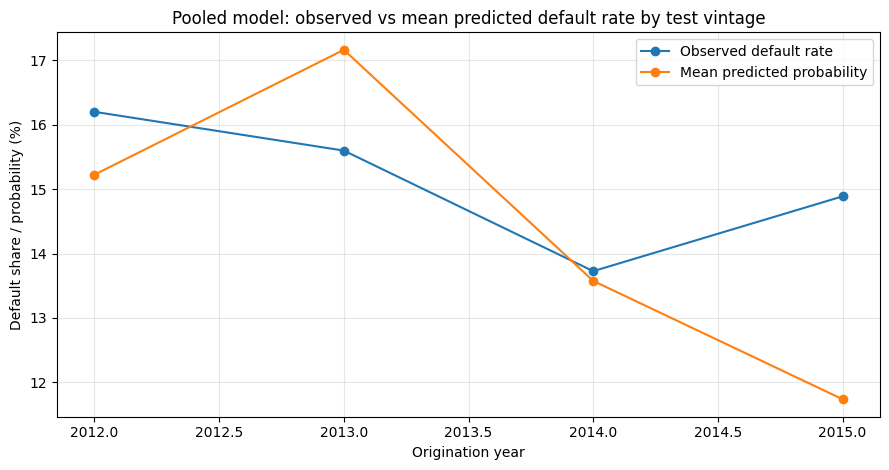

,segment_variable,segment,rows,defaults,actual_default_rate,mean_predicted_probability,predicted_default_rate,default_precision,default_recall,default_f1,roc_auc,reliability_flag
0,term,36,589488,82728,0.1403,0.1274,0.3937,0.2165,0.6073,0.3192,0.6679,sufficient group size
1,term,60,44279,11387,0.2572,0.2581,0.9223,0.2694,0.9661,0.4213,0.6158,sufficient group size
2,grade,A,134031,7324,0.0546,0.0559,0.0022,0.1621,0.0064,0.0123,0.6110,sufficient group size
3,grade,B,207807,23532,0.1132,0.1083,0.1735,0.1579,0.2419,0.1911,0.5677,sufficient group size
4,grade,C,171470,31490,0.1836,0.1635,0.7099,0.2024,0.7822,0.3216,0.5640,sufficient group size
5,grade,D,81110,19444,0.2397,0.2184,0.9394,0.2450,0.9599,0.3903,0.5556,sufficient group size
6,grade,E,28753,8571,0.2981,0.2563,0.9794,0.3005,0.9873,0.4608,0.5517,sufficient group size
7,grade,F,9048,3156,0.3488,0.3216,0.9915,0.3506,0.9965,0.5187,0.5524,sufficient group size
8,grade,G,1548,598,0.3863,0.3385,0.9942,0.3879,0.9983,0.5587,0.5143,sufficient group size
9,purpose,car,6235,762,0.1222,0.1224,0.3719,0.2031,0.6181,0.3057,0.6882,sufficient group size


,issue_year,term,rows,actual_default_rate,mean_predicted_probability,predicted_default_rate
0,2012,36,43470,0.1358,0.1312,0.3930
1,2012,60,9897,0.2770,0.2445,0.9062
2,2013,36,100422,0.1233,0.1406,0.4349
3,2013,60,34382,0.2515,0.2620,0.9269
4,2014,36,162570,0.1373,0.1358,0.3066
5,2015,36,283026,0.1489,0.1174,0.4293


In [8]:
pooled_predictions = experiment_predictions.get("Pooled", pd.DataFrame()).copy()
if pooled_predictions.empty:
    print("Pooled experiment produced no eligible out-of-time predictions; segment analysis skipped.")
else:
    by_year_rows = []
    for year, group in pooled_predictions.groupby("issue_year"):
        y_true = group["actual_default"].astype(int).to_numpy()
        y_pred = group["predicted_default"].astype(int).to_numpy()
        probabilities = group["predicted_probability"].to_numpy()
        by_year_rows.append({
            "issue_year": int(year),
            "rows": len(group),
            "actual_default_rate": y_true.mean(),
            "mean_predicted_probability": probabilities.mean(),
            "predicted_default_rate": y_pred.mean(),
            "default_precision": precision_score(y_true, y_pred, zero_division=0),
            "default_recall": recall_score(y_true, y_pred, zero_division=0),
            "default_f1": f1_score(y_true, y_pred, zero_division=0),
            "roc_auc": roc_auc_score(y_true, probabilities) if len(np.unique(y_true)) == 2 else np.nan,
        })
    pooled_year_metrics = pd.DataFrame(by_year_rows).sort_values("issue_year")
    display(pooled_year_metrics.round(4))
    pooled_year_metrics.to_csv(OUTPUT_DIR / "pooled_test_metrics_by_year.csv", index=False)

    fig, ax = plt.subplots(figsize=(9, 4.8))
    ax.plot(pooled_year_metrics["issue_year"], pooled_year_metrics["actual_default_rate"] * 100,
            marker="o", label="Observed default rate")
    ax.plot(pooled_year_metrics["issue_year"], pooled_year_metrics["mean_predicted_probability"] * 100,
            marker="o", label="Mean predicted probability")
    ax.set_title("Pooled model: observed vs mean predicted default rate by test vintage")
    ax.set_xlabel("Origination year")
    ax.set_ylabel("Default share / probability (%)")
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    def segment_summary(predictions, group_column, min_rows=MIN_SEGMENT_ROWS,
                        min_defaults=MIN_SEGMENT_DEFAULTS, min_non_defaults=MIN_SEGMENT_NONDEFAULTS):
        rows = []
        if group_column not in predictions.columns:
            return pd.DataFrame()
        for segment, group in predictions.groupby(group_column, dropna=False):
            y_true = group["actual_default"].astype(int).to_numpy()
            y_pred = group["predicted_default"].astype(int).to_numpy()
            probabilities = group["predicted_probability"].to_numpy()
            defaults = int(y_true.sum())
            non_defaults = int(len(y_true) - defaults)
            reliable = (
                len(group) >= min_rows
                and defaults >= min_defaults
                and non_defaults >= min_non_defaults
            )
            rows.append({
                "segment_variable": group_column,
                "segment": "Missing" if pd.isna(segment) else str(segment),
                "rows": len(group),
                "defaults": defaults,
                "actual_default_rate": y_true.mean(),
                "mean_predicted_probability": probabilities.mean(),
                "predicted_default_rate": y_pred.mean(),
                "default_precision": precision_score(y_true, y_pred, zero_division=0) if reliable else np.nan,
                "default_recall": recall_score(y_true, y_pred, zero_division=0) if reliable else np.nan,
                "default_f1": f1_score(y_true, y_pred, zero_division=0) if reliable else np.nan,
                "roc_auc": roc_auc_score(y_true, probabilities) if reliable and len(np.unique(y_true)) == 2 else np.nan,
                "reliability_flag": "sufficient group size" if reliable else "small / few defaults; descriptive only",
            })
        return pd.DataFrame(rows)

    segment_frames = []
    for col in ["term", "grade", "purpose"]:
        result = segment_summary(pooled_predictions, col)
        if not result.empty:
            segment_frames.append(result)
    pooled_segment_metrics = pd.concat(segment_frames, ignore_index=True) if segment_frames else pd.DataFrame()
    display(pooled_segment_metrics.round(4))
    pooled_segment_metrics.to_csv(OUTPUT_DIR / "pooled_segment_metrics.csv", index=False)

    # Explicit year-by-term summary, useful because the later test vintages may contain only 36-month loans.
    year_term_summary = (
        pooled_predictions.groupby(["issue_year", "term"])
        .agg(
            rows=("actual_default", "size"),
            actual_default_rate=("actual_default", "mean"),
            mean_predicted_probability=("predicted_probability", "mean"),
            predicted_default_rate=("predicted_default", "mean"),
        )
        .reset_index()
    )
    display(year_term_summary.round(4))
    year_term_summary.to_csv(OUTPUT_DIR / "pooled_test_metrics_by_year_and_term.csv", index=False)

## 8. Probability calibration diagnostics

The selected-model probabilities are sigmoid-calibrated using training-period data only. The reliability table groups out-of-time predictions into quantile bins. Well-calibrated probabilities should have observed default frequencies close to their mean predicted probabilities. Calibration can still deteriorate when the economic or lending environment shifts.

,probability_bin,rows,mean_predicted_probability,observed_default_rate
0,0,63377,0.0411,0.0371
1,1,63377,0.0611,0.0660
2,2,63376,0.0790,0.0910
3,3,63377,0.0964,0.1057
4,4,63377,0.1142,0.1251
5,5,63376,0.1331,0.1488
6,6,63377,0.1542,0.1754
7,7,63376,0.1793,0.2026
8,8,63377,0.2140,0.2333
9,9,63377,0.2931,0.3000


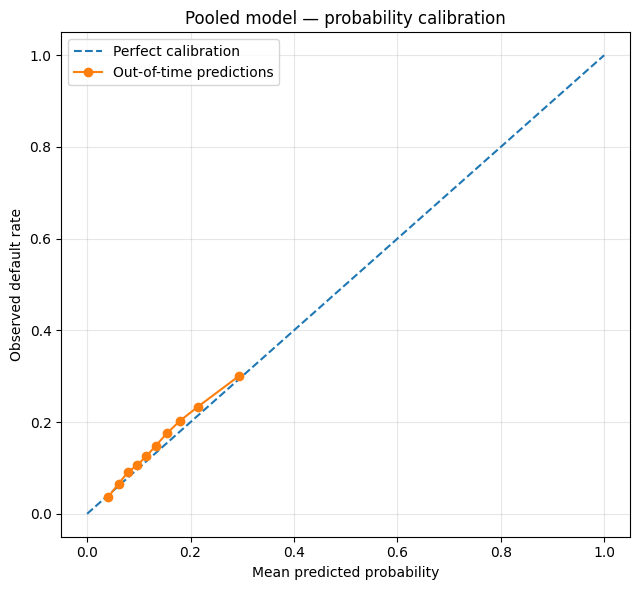

Pooled out-of-time Brier score: 0.1207


In [9]:
if pooled_predictions.empty:
    print("No pooled predictions available; calibration diagnostics skipped.")
else:
    calibration_frame = pooled_predictions[["actual_default", "predicted_probability"]].copy()
    calibration_frame["probability_bin"] = pd.qcut(
        calibration_frame["predicted_probability"],
        q=10,
        labels=False,
        duplicates="drop",
    )
    calibration_bins = (
        calibration_frame.groupby("probability_bin", observed=True)
        .agg(
            rows=("actual_default", "size"),
            mean_predicted_probability=("predicted_probability", "mean"),
            observed_default_rate=("actual_default", "mean"),
        )
        .reset_index()
    )
    display(calibration_bins.round(4))
    calibration_bins.to_csv(OUTPUT_DIR / "pooled_calibration_bins.csv", index=False)

    fig, ax = plt.subplots(figsize=(6.5, 6))
    ax.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")
    ax.plot(
        calibration_bins["mean_predicted_probability"],
        calibration_bins["observed_default_rate"],
        marker="o",
        label="Out-of-time predictions",
    )
    ax.set_title("Pooled model — probability calibration")
    ax.set_xlabel("Mean predicted probability")
    ax.set_ylabel("Observed default rate")
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    pooled_y = pooled_predictions["actual_default"].astype(int).to_numpy()
    pooled_prob = pooled_predictions["predicted_probability"].to_numpy()
    print("Pooled out-of-time Brier score:", round(brier_score_loss(pooled_y, pooled_prob), 4))

## 9. Final interpretation checklist and limitations

Before writing the project report, use the generated CSVs and answer these questions:

1. Does the pooled model outperform the simple no-skill average-precision baseline (the observed default prevalence)?
2. Is performance consistent across the 2012–2015 test vintages, or does it deteriorate in particular years?
3. Does adding origination year/quarter improve validation average precision consistently, rather than in one fold only?
4. Does the pooled model behave differently for 36- and 60-month loans?
5. Are the selected thresholds operationally sensible, given the resulting false-positive rate and default precision?
6. Does sigmoid calibration improve Brier score and the reliability plot?
7. Are grade/purpose segments supported by enough observations before interpreting their metrics?

### Limitations to state explicitly

- The dataset has a resolved-status target, not a precise event-time target. It cannot directly support a rigorous fixed-horizon default label or survival model without more detailed loan-performance history.
- The 99.5% resolved-cohort filter reduces outcome-maturity imbalance but does not guarantee equal follow-up or eliminate selection bias.
- The apparent snapshot observation date is inferred from available date fields; `last_pymnt_d` and `last_credit_pull_d` are not definitive dataset-wide cutoff metadata.
- Macroeconomic indicators are not yet merged. Year/quarter are only coarse proxies and must not be interpreted causally.
- The sample version can make the 60-month estimates unstable. Prefer the full 676,302 eligible rows for final work.
- Borrower identifiers were removed upstream, so repeated borrowers cannot be isolated across train/test partitions.
- `grade`, `sub_grade` and `int_rate` assume prediction at origination after underwriting. A different prediction point requires a different feature set.

### Output files

The notebook writes fold plans, validation comparisons, test comparisons, calibrated selected-model results, out-of-time predictions, year/segment tables and calibration bins into `outputs/`.

In [10]:
# Compact file inventory for reproducibility.
expected_outputs = [
    "temporal_fold_plan.csv",
    "validation_model_comparison.csv",
    "test_metrics_by_model_and_fold.csv",
    "aggregate_test_metrics_by_model.csv",
    "selected_model_metrics_by_fold.csv",
    "selected_model_aggregate_test_metrics.csv",
    "pooled_out_of_time_predictions.csv",
    "36month_out_of_time_predictions.csv",
    "60month_out_of_time_predictions.csv",
    "pooled_test_metrics_by_year.csv",
    "pooled_segment_metrics.csv",
    "pooled_calibration_bins.csv",
]
output_inventory = pd.DataFrame({
    "file": expected_outputs,
    "created": [(OUTPUT_DIR / name).exists() for name in expected_outputs],
})
display(output_inventory)
print("Notebook 3 completed. Output directory:", OUTPUT_DIR)

,file,created
0,temporal_fold_plan.csv,True
1,validation_model_comparison.csv,True
2,test_metrics_by_model_and_fold.csv,True
3,aggregate_test_metrics_by_model.csv,True
4,selected_model_metrics_by_fold.csv,True
5,selected_model_aggregate_test_metrics.csv,True
6,pooled_out_of_time_predictions.csv,True
7,36month_out_of_time_predictions.csv,True
8,60month_out_of_time_predictions.csv,True
9,pooled_test_metrics_by_year.csv,True


Notebook 3 completed. Output directory: n:\SARANYA\GITRepositories\APPS\credit_risk_analytics\outputs
